In [1]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
student_data = pd.read_csv('Student_Data.csv')
student_data

,StudyHours,Attendance,AssignmentScore,ExamScore,Extracurricular,SocialMedia,SleepHours
0,11.2,76,57,68,13.0,4.8,6.8
1,10.2,72,69,59,9.9,5.6,6.7
2,19.4,85,75,79,10.9,2.9,5.8
3,13.1,76,66,65,12.6,5.0,6.8
4,5.1,81,64,55,11.0,6.0,6.7
...,...,...,...,...,...,...,...
95,12.4,77,58,68,9.6,6.4,6.2
96,19.9,93,83,85,0.0,2.6,7.9
97,10.1,74,58,43,0.7,4.4,8.0
98,17.0,90,77,70,0.0,2.0,7.6


In [3]:
# 7 input (kriteria), tanpa output / label
feature_names = list(student_data.columns)
X = student_data.values
feature_names

['StudyHours',
 'Attendance',
 'AssignmentScore',
 'ExamScore',
 'Extracurricular',
 'SocialMedia',
 'SleepHours']

In [4]:
X.shape

(100, 7)

In [5]:
student_data.describe().round(2)

,StudyHours,Attendance,AssignmentScore,ExamScore,Extracurricular,SocialMedia,SleepHours
count,100.00,100.00,100.00,100.00,100.00,100.00,100.00
mean,14.47,81.78,70.91,66.21,6.48,4.06,7.00
std,7.24,11.28,12.87,13.64,4.98,1.42,0.94
min,1.00,58.00,46.00,40.00,0.00,0.50,4.90
25%,8.15,74.00,60.00,53.75,1.55,2.90,6.30
50%,14.15,82.50,72.00,67.50,7.05,4.10,7.00
75%,20.15,92.00,81.25,77.00,11.02,5.40,7.80
max,30.50,100.00,93.00,100.00,15.90,7.10,9.30


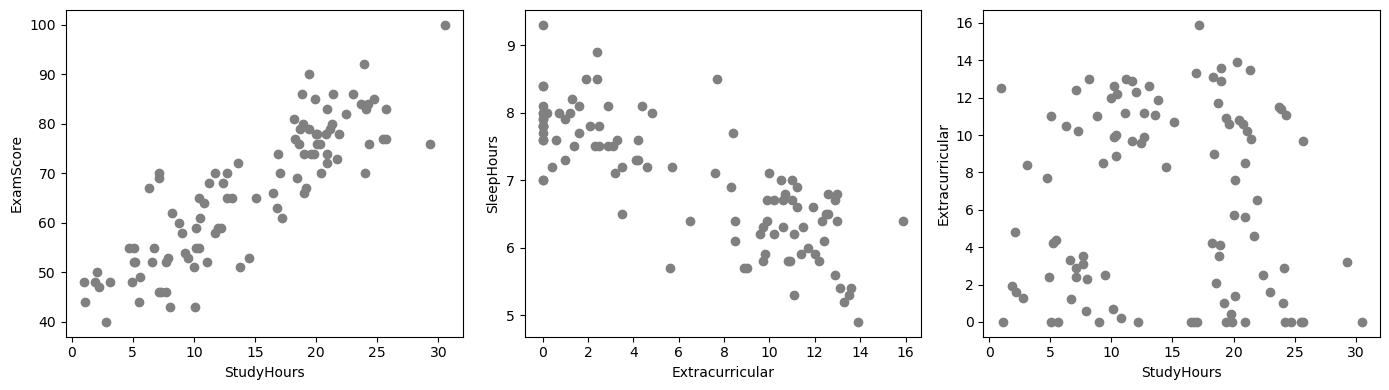

In [6]:
# Visualization
# with 7 features there are 21 pairs of features, every scatter plot only shows a small part of the data
pairs = [('StudyHours', 'ExamScore'), ('Extracurricular', 'SleepHours'), ('StudyHours', 'Extracurricular')]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (fx, fy) in zip(axes, pairs):
    ax.scatter(student_data[fx], student_data[fy], c='gray')
    ax.set_xlabel(fx)
    ax.set_ylabel(fy)
fig.tight_layout()
plt.show()

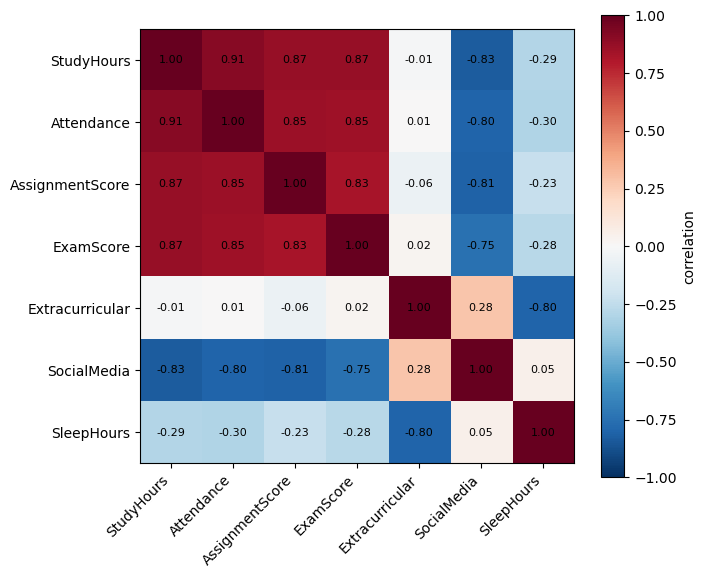

In [7]:
# Correlation matrix
# features with a strong correlation carry similar information, PCA can combine them into one component
corr = np.corrcoef(X, rowvar=False)

plt.figure(figsize=(7, 6))
plt.imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
plt.colorbar(label='correlation')
for i in range(len(feature_names)):
    for j in range(len(feature_names)):
        plt.text(j, i, f'{corr[i, j]:.2f}', ha='center', va='center', fontsize=8)
plt.xticks(range(len(feature_names)), feature_names, rotation=45, ha='right')
plt.yticks(range(len(feature_names)), feature_names)
plt.show()

In [8]:
# Feature Scaling (StandardScaler)
# the 7 features have very different scales (Attendance 0 - 100 %, SleepHours 4 - 9 hours, ...).
# PCA and K-Means both depend on the variance / distance, so every feature must have the same scale first.
# StandardScaler changes every feature to mean = 0 and standard deviation = 1: z = (x - mean) / std
class StandardScaler:
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        X = np.array(X, dtype=float)
        self.mean_ = X.mean(axis=0)
        self.std_ = X.std(axis=0)
        return self

    def transform(self, X):
        X = np.array(X, dtype=float)
        return (X - self.mean_) / self.std_

In [9]:
scaler = StandardScaler().fit(X)
X_scaled = scaler.transform(X)
X_scaled[:5].round(3)

array([[-0.455, -0.515, -1.087,  0.132,  1.316,  0.522, -0.214],
       [-0.594, -0.872, -0.149, -0.531,  0.69 ,  1.089, -0.321],
       [ 0.684,  0.287,  0.319,  0.943,  0.892, -0.825, -1.285],
       [-0.191, -0.515, -0.384, -0.089,  1.235,  0.663, -0.214],
       [-1.302, -0.07 , -0.54 , -0.826,  0.912,  1.372, -0.321]])

In [10]:
# PCA (Principal Component Analysis) Implementation
# PCA finds new axes (principal components) that point in the directions where the data varies the most.
# PC1 keeps the most information (variance), PC2 the second most, and so on.
# by keeping only the first few components, 7 features can be compressed into 2 while keeping most of the information.
class PCA:
    def __init__(self, n_components=None):
        self.n_components = n_components
        self.mean_ = None
        self.components_ = None
        self.explained_variance_ = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        X = np.array(X, dtype=float)

        # 1. center the data (mean = 0)
        self.mean_ = X.mean(axis=0)
        X_centered = X - self.mean_

        # 2. covariance matrix (n_features x n_features): how every pair of features varies together
        cov = X_centered.T @ X_centered / (len(X) - 1)

        # 3. eigen decomposition: eigenvectors = directions of the new axes, eigenvalues = variance along each axis
        eigenvalues, eigenvectors = np.linalg.eigh(cov)

        # 4. sort from the largest to the smallest variance
        order = np.argsort(eigenvalues)[::-1]
        eigenvalues = eigenvalues[order]
        eigenvectors = eigenvectors[:, order]

        # an eigenvector can point in two opposite directions, make the largest loading positive so the result is always the same
        largest = np.argmax(np.abs(eigenvectors), axis=0)
        eigenvectors = eigenvectors * np.sign(eigenvectors[largest, range(len(largest))])

        # 5. keep the first n_components
        n = self.n_components or X.shape[1]
        self.components_ = eigenvectors[:, :n].T   # shape (n_components, n_features)
        self.explained_variance_ = eigenvalues[:n]
        self.explained_variance_ratio_ = eigenvalues[:n] / eigenvalues.sum()
        return self

    def transform(self, X):
        # project the data onto the principal components
        X = np.array(X, dtype=float)
        return (X - self.mean_) @ self.components_.T

In [11]:
# PCA with all components, to see how much information every component keeps
pca_full = PCA().fit(X_scaled)
print('explained variance ratio: ', pca_full.explained_variance_ratio_.round(3))
print('cumulative              : ', np.cumsum(pca_full.explained_variance_ratio_).round(3))

explained variance ratio:  [0.632 0.262 0.032 0.023 0.02  0.018 0.012]
cumulative              :  [0.632 0.895 0.927 0.95  0.97  0.988 1.   ]


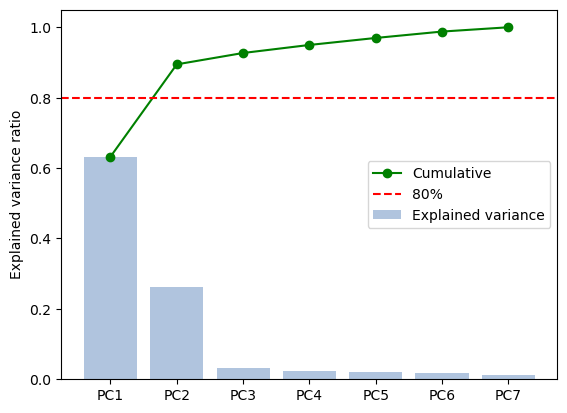

In [12]:
# Scree plot
# bar = information kept by every component, line = total information kept by the first n components
components = np.arange(1, len(feature_names) + 1)

plt.bar(components, pca_full.explained_variance_ratio_, color='lightsteelblue', label='Explained variance')
plt.plot(components, np.cumsum(pca_full.explained_variance_ratio_), 'o-', c='g', label='Cumulative')
plt.axhline(0.8, c='r', ls='--', label='80%')
plt.xticks(components, [f'PC{i}' for i in components])
plt.ylabel('Explained variance ratio')
plt.legend(loc='center right')
plt.show()

In [13]:
# keep 2 components: 7 features -> 2 features
pca = PCA(n_components=2).fit(X_scaled)
X_pca = pca.transform(X_scaled)

print('X_scaled: ', X_scaled.shape)
print('X_pca   : ', X_pca.shape)
print('information kept: ', pca.explained_variance_ratio_.sum().round(3))

X_scaled:  (100, 7)
X_pca   :  (100, 2)
information kept:  0.895


In [14]:
# Loadings: contribution of every original feature to PC1 and PC2
loadings = pd.DataFrame(pca.components_.T, index=feature_names, columns=['PC1', 'PC2'])
loadings.round(3)

,PC1,PC2
StudyHours,0.458,-0.003
Attendance,0.451,0.011
AssignmentScore,0.443,-0.042
ExamScore,0.439,0.018
Extracurricular,-0.004,0.713
SocialMedia,-0.419,0.215
SleepHours,-0.150,-0.666


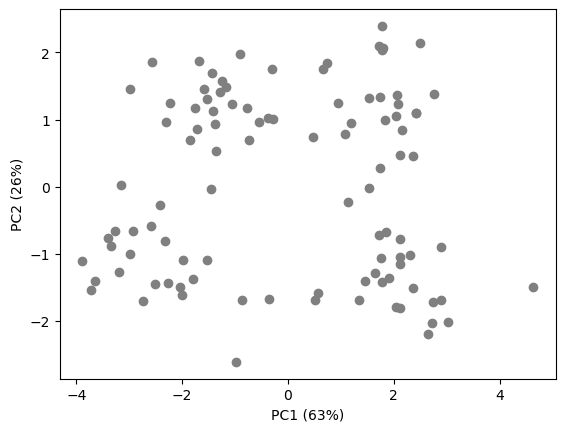

In [15]:
# Visualization in the PCA space
# all 7 features are now summarized in 2 axes, and the groups become visible

plt.scatter(X_pca[:, 0], X_pca[:, 1], c='gray')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.show()

In [16]:
# K-Means Implementation
# the KMeans class groups the data into n_clusters groups without using any label.
# fit starts with K random samples as centroids, then repeats two steps until the centroids stop moving:
#   1. assignment step: every sample joins the cluster of its closest centroid
#   2. update step    : every centroid moves to the mean of the samples in its cluster
# centroid_history_, labels_history_ and inertia_history_ store every iteration (used for the animation).
class KMeans:
    def __init__(self, n_clusters=3, max_iter=100, random_state=None):
        self.n_clusters = n_clusters
        self.max_iter = max_iter
        self.random_state = random_state
        self.centroids_ = None
        self.labels_ = None
        self.inertia_ = None
        self.centroid_history_ = []
        self.labels_history_ = []
        self.inertia_history_ = []

    def _distances(self, X, centroids):
        # Euclidean distance from every sample to every centroid -> shape (n_samples, n_clusters)
        return np.array([np.sqrt(np.sum((X - c) ** 2, axis=1)) for c in centroids]).T

    def _inertia(self, X, labels, centroids):
        # sum of squared distances from every sample to its own centroid
        return np.sum((X - centroids[labels]) ** 2)

    # Training
    def fit(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        # initialization: pick K random samples as the first centroids
        rng = np.random.RandomState(self.random_state)
        centroids = X[rng.choice(len(X), self.n_clusters, replace=False)]

        self.centroid_history_ = [centroids.copy()]
        self.labels_history_ = []
        self.inertia_history_ = []

        for _ in range(self.max_iter):
            # 1. assignment step
            labels = np.argmin(self._distances(X, centroids), axis=1)

            # 2. update step (an empty cluster keeps its old centroid)
            new_centroids = np.array([X[labels == k].mean(axis=0) if np.any(labels == k) else centroids[k]
                                      for k in range(self.n_clusters)])

            self.labels_history_.append(labels)
            self.inertia_history_.append(self._inertia(X, labels, centroids))
            self.centroid_history_.append(new_centroids.copy())

            # stop when the centroids do not move anymore (converged)
            if np.allclose(new_centroids, centroids):
                break
            centroids = new_centroids

        self.centroids_ = centroids
        self.labels_ = labels
        self.inertia_ = self._inertia(X, labels, centroids)
        return self

    # Testing: a new sample joins the cluster of its closest centroid
    def predict(self, X):
        X = np.array(X, dtype=float)

        if X.ndim == 1:
            X = X.reshape(-1, 1)

        return np.argmin(self._distances(X, self.centroids_), axis=1)

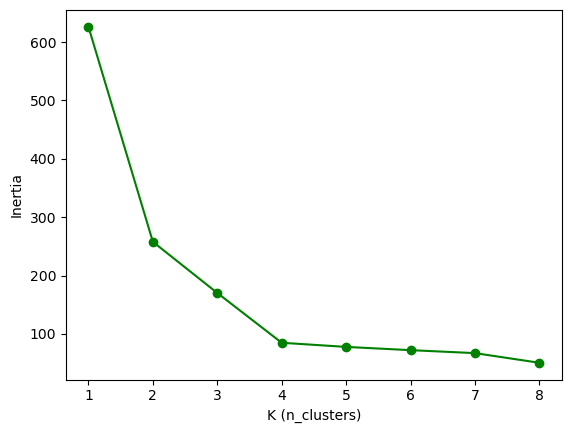

In [17]:
# Elbow Method
# inertia always goes down when K goes up, choose K at the "elbow" where the curve starts to flatten
k_values = range(1, 9)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=1).fit(X_pca)
    inertias.append(model.inertia_)

plt.plot(k_values, inertias, 'o-', c='g')
plt.xlabel('K (n_clusters)')
plt.ylabel('Inertia')
plt.show()

In [18]:
#Fitting Model on the PCA result
kmeans = KMeans(n_clusters=4, random_state=1)
kmeans.fit(X_pca)

In [19]:
print('number of iterations: ', len(kmeans.labels_history_))
print('inertia: ', kmeans.inertia_)
print('centroids (PCA space):')
print(kmeans.centroids_.round(3))

number of iterations:  9
inertia:  84.94404269703202
centroids (PCA space):
[[-1.383  1.21 ]
 [ 2.098 -1.369]
 [-2.498 -1.173]
 [ 1.739  1.238]]


In [20]:
# cluster of every student
kmeans.labels_

array([0, 0, 3, 0, 0, 1, 3, 0, 2, 2, 0, 3, 2, 2, 2, 3, 3, 3, 0, 1, 1, 0,
       0, 2, 1, 3, 0, 3, 3, 3, 2, 0, 2, 0, 0, 3, 3, 2, 1, 3, 0, 2, 0, 1,
       0, 3, 3, 0, 3, 0, 3, 2, 1, 1, 2, 3, 1, 0, 1, 2, 3, 2, 2, 3, 3, 0,
       1, 2, 1, 0, 2, 1, 2, 2, 1, 0, 1, 2, 0, 1, 3, 3, 1, 1, 1, 2, 3, 1,
       2, 0, 1, 1, 2, 0, 1, 0, 1, 2, 1, 3])

In [21]:
# # Animation: how the centroids move during training (in the PCA space)
# # frame 0 = random initial centroids (no cluster yet), then one frame per iteration:
# # the students are colored by their cluster, the crosses are the centroids, the lines are the path of every centroid.
# from matplotlib.animation import FuncAnimation, PillowWriter
# from IPython.display import HTML

# colors = np.array(['tab:blue', 'tab:orange', 'tab:green', 'tab:red'])
# centroid_history = np.array(kmeans.centroid_history_)
# labels_history = kmeans.labels_history_
# inertia_history = kmeans.inertia_history_
# n_frames = len(labels_history) + 1

# fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4.5), dpi=80)

# def update(i):
#     # left: students colored by cluster + centroids and their path
#     ax1.clear()
#     if i == 0:
#         ax1.scatter(X_pca[:, 0], X_pca[:, 1], c='gray', alpha=0.6)
#         title = 'Initialization: random centroids'
#     else:
#         ax1.scatter(X_pca[:, 0], X_pca[:, 1], c=colors[labels_history[i - 1]], alpha=0.6)
#         title = f'Iteration {i}  |  inertia = {inertia_history[i - 1]:.2f}'
#     for k in range(kmeans.n_clusters):
#         ax1.plot(centroid_history[:i + 1, k, 0], centroid_history[:i + 1, k, 1], c='k', lw=1)
#         ax1.scatter(centroid_history[i, k, 0], centroid_history[i, k, 1], c=colors[k], marker='X', s=250, edgecolors='k')
#     ax1.set_xlim(X_pca[:, 0].min() - 0.5, X_pca[:, 0].max() + 0.5)
#     ax1.set_ylim(X_pca[:, 1].min() - 0.5, X_pca[:, 1].max() + 0.5)
#     ax1.set_xlabel('PC1')
#     ax1.set_ylabel('PC2')
#     ax1.set_title(title)

#     # right: inertia for every iteration, the dot shows the current iteration
#     ax2.clear()
#     iterations = np.arange(1, len(inertia_history) + 1)
#     ax2.plot(iterations, inertia_history, 'o-', c='lightgray')
#     if i > 0:
#         ax2.plot(iterations[:i], inertia_history[:i], 'o-', c='g')
#         ax2.plot([i], [inertia_history[i - 1]], 'o', c='r', ms=10)
#     ax2.set_xticks(iterations)
#     ax2.set_xlabel('Iteration')
#     ax2.set_ylabel('Inertia')
#     ax2.set_title('Inertia')

# update(0)
# fig.tight_layout()

# anim = FuncAnimation(fig, update, frames=range(n_frames), interval=1000)
# plt.close(fig)

# plt.rcParams['animation.frame_format'] = 'jpeg'  # smaller notebook file than png frames
# HTML(anim.to_jshtml())

In [22]:
# # Save the animation as a GIF (for slides / sharing)
# anim.save('training_animation.gif', writer=PillowWriter(fps=1))

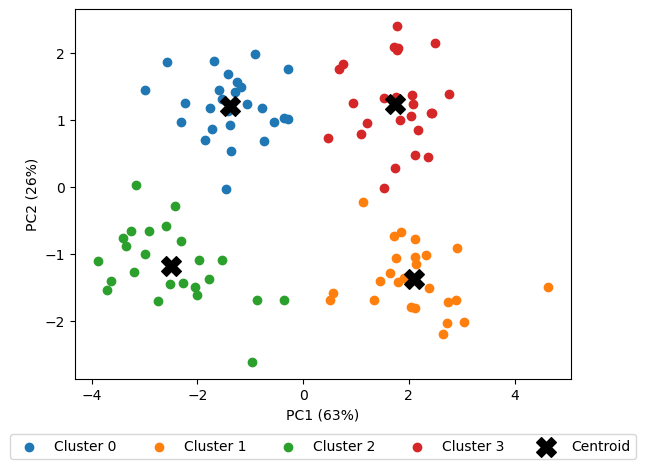

In [23]:
# Visualization
# every color is one cluster, X = centroid

colors = np.array(['tab:blue', 'tab:orange', 'tab:green', 'tab:red'])

for k in range(kmeans.n_clusters):
    plt.scatter(X_pca[kmeans.labels_ == k, 0], X_pca[kmeans.labels_ == k, 1], c=colors[k], label=f'Cluster {k}')
plt.scatter(kmeans.centroids_[:, 0], kmeans.centroids_[:, 1], c='k', marker='X', s=200, label='Centroid')
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.13), ncol=5)
plt.show()

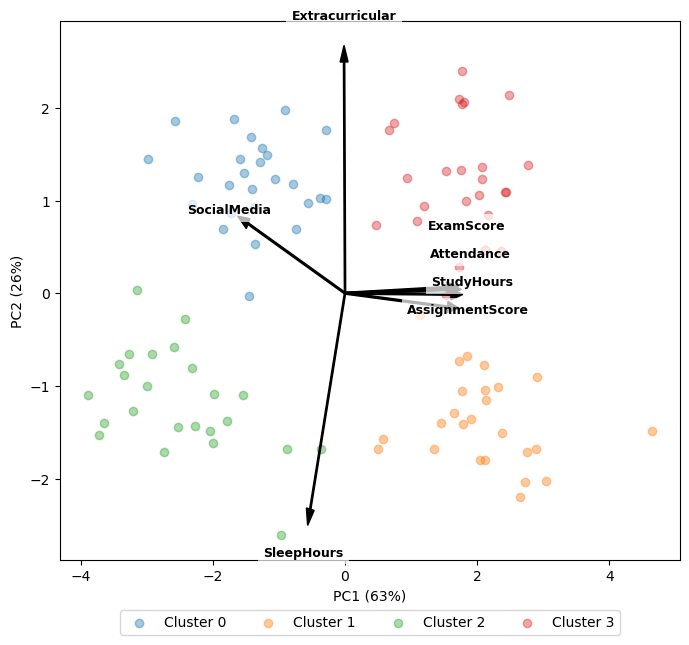

In [24]:
# Biplot: clusters + loading arrows
# every arrow is one original feature, it points to the direction where that feature increases
plt.figure(figsize=(8, 7))
for k in range(kmeans.n_clusters):
    plt.scatter(X_pca[kmeans.labels_ == k, 0], X_pca[kmeans.labels_ == k, 1], c=colors[k], alpha=0.4, label=f'Cluster {k}')

scale = 3.5   # make the arrows longer so they are easier to see
arrows = pca.components_.T * scale
label_pos = arrows * 1.2

# arrows that point in almost the same direction have overlapping labels, so push those labels apart vertically
order = np.argsort(label_pos[:, 1])
for prev, cur in zip(order[:-1], order[1:]):
    if abs(label_pos[cur, 0] - label_pos[prev, 0]) < 1.5 and label_pos[cur, 1] - label_pos[prev, 1] < 0.3:
        label_pos[cur, 1] = label_pos[prev, 1] + 0.3

for i, name in enumerate(feature_names):
    plt.arrow(0, 0, arrows[i, 0], arrows[i, 1], color='k', width=0.02, head_width=0.12)
    plt.text(label_pos[i, 0], label_pos[i, 1], name, ha='center', va='center', fontsize=9, fontweight='bold',
             bbox=dict(facecolor='white', edgecolor='none', alpha=0.7))
plt.xlabel(f'PC1 ({pca.explained_variance_ratio_[0]:.0%})')
plt.ylabel(f'PC2 ({pca.explained_variance_ratio_[1]:.0%})')
plt.legend(loc='upper center', bbox_to_anchor=(0.5, -0.08), ncol=4)
plt.show()

In [25]:
# compare: K-Means on all 7 (scaled) features vs K-Means on the 2 PCA components
# the cluster numbers can be different, but every row of the table should have only one non-zero value (same groups)
kmeans_full = KMeans(n_clusters=4, random_state=1).fit(X_scaled)
pd.crosstab(kmeans.labels_, kmeans_full.labels_, rownames=['PCA (2 features)'], colnames=['Original (7 features)'])

Original (7 features),0,1,2,3
PCA (2 features),,,,
0,26,0,0,0
1,0,25,0,0
2,0,0,24,0
3,0,0,0,25


In [26]:
# Cluster profiling: average of every original feature for every cluster
student_data['Cluster'] = kmeans.labels_
profile = student_data.groupby('Cluster').mean().round(1)
profile['n_students'] = student_data.groupby('Cluster').size()
profile

,StudyHours,Attendance,AssignmentScore,ExamScore,Extracurricular,SocialMedia,SleepHours,n_students
Cluster,,,,,,,,
0,10.0,75.1,62.2,59.2,10.8,5.3,6.5,26
1,21.6,92.6,82.7,79.0,1.5,2.5,7.6,25
2,6.1,68.5,57.9,50.8,2.3,5.1,8.1,24
3,20.1,90.7,80.6,75.6,10.9,3.3,6.0,25


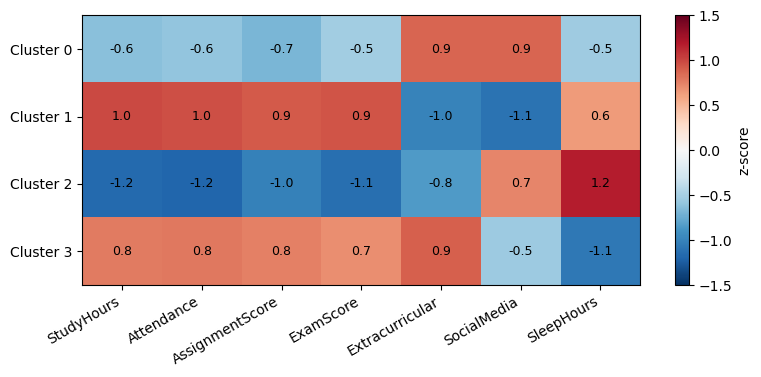

In [27]:
# Heatmap of the profile in z-score: red = above the average of all students, blue = below the average
profile_z = pd.DataFrame(scaler.transform(profile[feature_names]), index=profile.index, columns=feature_names)

plt.figure(figsize=(9, 3.5))
plt.imshow(profile_z, cmap='RdBu_r', vmin=-1.5, vmax=1.5, aspect='auto')
plt.colorbar(label='z-score')
for i in range(len(profile_z)):
    for j in range(len(feature_names)):
        plt.text(j, i, f'{profile_z.iloc[i, j]:.1f}', ha='center', va='center', fontsize=9)
plt.xticks(range(len(feature_names)), feature_names, rotation=30, ha='right')
plt.yticks(range(len(profile_z)), [f'Cluster {k}' for k in profile_z.index])
plt.show()

In [28]:
# describe every cluster: features clearly above (z > 0.5) or below (z < -0.5) the average
def describe(row):
    high = [f for f in feature_names if row[f] > 0.5]
    low = [f for f in feature_names if row[f] < -0.5]
    return 'tinggi: ' + (', '.join(high) or '-') + '  |  rendah: ' + (', '.join(low) or '-')

pd.set_option('display.max_colwidth', None)
profile_z.apply(describe, axis=1).to_frame('description')

,description
Cluster,
0,"tinggi: Extracurricular, SocialMedia | rendah: StudyHours, Attendance, AssignmentScore, ExamScore, SleepHours"
1,"tinggi: StudyHours, Attendance, AssignmentScore, ExamScore, SleepHours | rendah: Extracurricular, SocialMedia"
2,"tinggi: SocialMedia, SleepHours | rendah: StudyHours, Attendance, AssignmentScore, ExamScore, Extracurricular"
3,"tinggi: StudyHours, Attendance, AssignmentScore, ExamScore, Extracurricular | rendah: SocialMedia, SleepHours"


In [29]:
# new students: [StudyHours, Attendance, AssignmentScore, ExamScore, Extracurricular, SocialMedia, SleepHours]
# new data must go through the same steps: scaling -> PCA -> K-Means
new_students = [[22, 95, 85, 82, 2, 2.5, 7.5],
                [6, 70, 58, 50, 12, 5.0, 5.8]]

new_pca = pca.transform(scaler.transform(new_students))
prediksi = kmeans.predict(new_pca)
prediksi

array([1, 0])

In [30]:
profile_z.apply(describe, axis=1).loc[prediksi]

Cluster
1    tinggi: StudyHours, Attendance, AssignmentScore, ExamScore, SleepHours  |  rendah: Extracurricular, SocialMedia
0    tinggi: Extracurricular, SocialMedia  |  rendah: StudyHours, Attendance, AssignmentScore, ExamScore, SleepHours
dtype: object

# K-Means Clustering dengan PCA

Pada notebook sebelumnya, K-Means dipakai untuk data dengan **2 fitur**, sehingga hasilnya bisa langsung digambar. Di dunia nyata, data biasanya memiliki **banyak kriteria**. Pada notebook ini kita memakai data **profil mahasiswa** (`Student_Data.csv`) dengan 7 kriteria dan tanpa label:

| Kriteria | Keterangan |
|---|---|
| `StudyHours` | jam belajar mandiri per minggu |
| `Attendance` | persentase kehadiran kuliah (%) |
| `AssignmentScore` | rata-rata nilai tugas (0 – 100) |
| `ExamScore` | rata-rata nilai ujian (0 – 100) |
| `Extracurricular` | jam kegiatan organisasi / UKM per minggu |
| `SocialMedia` | jam bermain media sosial per hari |
| `SleepHours` | jam tidur per hari |

Tujuannya adalah menemukan **kelompok (tipe) mahasiswa** berdasarkan ketujuh kriteria tersebut.

## Masalah data dengan banyak dimensi

1. **Tidak bisa digambar.** Grafik hanya bisa 2D (atau 3D). Dengan 7 fitur ada $\binom{7}{2} = 21$ pasangan scatter plot, dan tidak ada satu pun yang menunjukkan gambaran lengkap.
2. **Banyak fitur yang saling berkorelasi.** Pada heatmap korelasi terlihat `StudyHours`, `Attendance`, `AssignmentScore`, dan `ExamScore` saling berkorelasi kuat. Keempatnya sebenarnya membawa informasi yang mirip ("seberapa akademis" mahasiswa tersebut).
3. **Curse of dimensionality.** Semakin banyak dimensi, jarak antar data semakin mirip satu sama lain, sehingga algoritma berbasis jarak seperti K-Means menjadi kurang efektif. Fitur yang hanya berisi noise juga ikut memengaruhi jarak.

Solusinya adalah **PCA**.

## Algoritma PCA (Principal Component Analysis)

PCA adalah teknik **reduksi dimensi** yang membuat sumbu-sumbu baru (**principal component**) dari kombinasi fitur-fitur asli:

$$
PC_1 = w_{11} x_1 + w_{12} x_2 + \dots + w_{17} x_7
$$

- **PC1** adalah arah di mana data paling bervariasi (menyimpan informasi paling banyak)
- **PC2** adalah arah dengan variasi terbesar kedua, dan **tegak lurus** dengan PC1
- dan seterusnya sampai PC7

Bobot $w$ disebut **loading**. Loading menunjukkan seberapa besar kontribusi setiap fitur asli pada principal component tersebut.

### Langkah-langkah PCA

#### 1. Standardisasi data
PCA mencari arah dengan variansi terbesar. Tanpa scaling, fitur dengan angka besar (misalnya `Attendance`) akan mendominasi. Karena itu data di-standardisasi dulu:

$$
z = \frac{x - \mu}{\sigma}
$$

#### 2. Hitung matriks kovarians

$$
C = \frac{1}{n - 1} X^T X
$$

$C$ berukuran $7 \times 7$. Elemen $C_{ij}$ menunjukkan bagaimana fitur $i$ dan fitur $j$ bervariasi bersama.

```python
cov = X_centered.T @ X_centered / (len(X) - 1)
```

#### 3. Eigen decomposition

$$
C v = \lambda v
$$

- **eigenvector** $v$ = arah principal component (berisi loading)
- **eigenvalue** $\lambda$ = besar variansi data pada arah tersebut

```python
eigenvalues, eigenvectors = np.linalg.eigh(cov)
```

#### 4. Urutkan dari variansi terbesar
Eigenvector dengan eigenvalue terbesar menjadi PC1, terbesar kedua menjadi PC2, dan seterusnya.

#### 5. Explained variance ratio
Proporsi informasi yang disimpan oleh setiap komponen:

$$
\text{explained variance ratio}_k = \frac{\lambda_k}{\sum_{j} \lambda_j}
$$

Pada data ini, **PC1 + PC2 menyimpan sekitar 90% informasi** dari 7 fitur. Artinya 7 dimensi bisa diringkas menjadi 2 dimensi tanpa kehilangan banyak informasi. Grafik *scree plot* membantu memilih jumlah komponen. Aturan umum yang sering dipakai: ambil komponen secukupnya sampai total explained variance mencapai 80 – 90%.

#### 6. Transformasi (proyeksi)
Data diproyeksikan ke principal component yang dipilih:

$$
X_{PCA} = (X - \mu) \, W^T
$$

```python
return (X - self.mean_) @ self.components_.T
```

Hasilnya adalah data baru berukuran $100 \times 2$ yang bisa digambar dan di-cluster.

### Membaca loading

Tabel loading menunjukkan arti setiap principal component:
- **PC1** didominasi oleh `StudyHours`, `Attendance`, `AssignmentScore`, `ExamScore` (dan `SocialMedia` dengan tanda berlawanan) → PC1 dapat dibaca sebagai **"tingkat akademik"**
- **PC2** didominasi oleh `Extracurricular` dan `SleepHours` dengan tanda berlawanan → PC2 dapat dibaca sebagai **"tingkat keaktifan organisasi"**

**Biplot** menggambar data dan panah loading sekaligus. Panah menunjukkan arah di mana nilai sebuah fitur meningkat.

## K-Means pada hasil PCA

Setelah data diringkas menjadi 2 komponen, K-Means dijalankan pada `X_pca`, persis seperti notebook K-Means sebelumnya:

1. Pilih $K$ centroid awal secara acak
2. **Assignment step**: setiap data masuk ke cluster dengan centroid terdekat
3. **Update step**: centroid dipindahkan ke rata-rata data di cluster-nya
4. Ulangi sampai centroid tidak bergerak (konvergen)

Jumlah cluster dipilih dengan **elbow method**. Pada data ini siku berada di **K = 4**.

Keuntungan menjalankan K-Means pada hasil PCA:
- hasil clustering bisa **divisualisasikan** dalam 2D (termasuk animasinya)
- noise pada komponen-komponen kecil dibuang
- perhitungan jarak lebih cepat karena dimensinya lebih sedikit

Pada sel perbandingan (*crosstab*), K-Means pada 7 fitur asli dan K-Means pada 2 komponen PCA menghasilkan kelompok yang **sama** (hanya nomor cluster-nya yang bisa berbeda). Artinya PCA berhasil menyimpan informasi yang penting untuk clustering.

## Interpretasi Cluster

PCA membantu menemukan dan menggambar cluster, tetapi **interpretasi tetap dilakukan dengan fitur asli**. Caranya adalah menghitung rata-rata setiap fitur untuk setiap cluster (**cluster profiling**):
- tabel rata-rata dalam satuan asli (jam, %, nilai)
- heatmap z-score: merah = di atas rata-rata, biru = di bawah rata-rata

Dari profil tersebut, setiap cluster bisa diberi nama, misalnya:
- akademik tinggi, organisasi rendah → **mahasiswa akademis**
- akademik cukup tinggi, organisasi tinggi → **mahasiswa aktivis berprestasi**
- akademik rendah, organisasi rendah, media sosial tinggi → **mahasiswa kurang aktif**, perlu pendampingan
- akademik rendah, organisasi tinggi → **mahasiswa sibuk organisasi**, perlu bantuan membagi waktu

## Prediksi data baru

Data mahasiswa baru harus melewati langkah yang **sama dan berurutan**, menggunakan scaler, PCA, dan K-Means yang sudah di-fit:

```python
new_scaled = scaler.transform(new_student)   # 1. scaling
new_pca = pca.transform(new_scaled)          # 2. proyeksi PCA
cluster = kmeans.predict(new_pca)            # 3. centroid terdekat
```

## Intuisi sederhana

Bayangkan memotret sebuah benda 3D (misalnya teko) agar bentuknya paling mudah dikenali. Dari atas, teko terlihat seperti lingkaran. Dari samping, terlihat badan, cerat, dan pegangannya. PCA mencari **sudut pandang terbaik** seperti itu, yaitu sudut yang memperlihatkan perbedaan antar data paling jelas. Setelah itu K-Means mengelompokkan data pada "foto" tersebut.

## Kesimpulan

K-Means dengan PCA bekerja dengan cara:

1. Menyiapkan data dengan banyak kriteria tanpa label
2. Melakukan feature scaling
3. Menghitung matriks kovarians, eigenvector, dan eigenvalue (PCA)
4. Memilih jumlah komponen dengan explained variance (scree plot)
5. Memproyeksikan data ke principal component (7 dimensi → 2 dimensi)
6. Memilih $K$ dengan elbow method, lalu menjalankan K-Means pada hasil PCA
7. Menginterpretasikan setiap cluster dengan rata-rata fitur asli

Itulah dasar penggunaan PCA untuk membantu K-Means pada data multi-dimensi.